In [ ]:
# Table for daily Trading ~250 trading days/ year

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load and Inspect the Raw Share Price Dataset

The Share Prices dataset contains daily market information for companies in the selected investment universe. Before filtering or transforming the data, we first inspect its size, structure, data types, and missing values.

This initial inspection helps us understand the dataset and identify potential data-quality issues before performing any cleaning.

In [ ]:
df_prices = pd.read_csv("/content/drive/MyDrive/data_handling_and_machine_learning/week_03/raw/share_prices.csv", sep=";")

In [ ]:
selected_comp = pd.read_excel("/content/drive/MyDrive/data_handling_and_machine_learning/week_03/raw/100_companies.xlsx")

**Dataset Overview**

We inspect the number of observations and variables to understand the scale of the raw dataset.

In [ ]:
print("Shape:", df_prices.shape)

print("\nColumns:")
print(df_prices.columns)


Shape: (6218102, 11)

Columns:
Index(['Ticker', 'SimFinId', 'Date', 'Open', 'High', 'Low', 'Close',
       'Adj. Close', 'Volume', 'Dividend', 'Shares Outstanding'],
      dtype='object')


In [ ]:
df_prices.head(10)

,Ticker,SimFinId,Date,Open,High,Low,Close,Adj. Close,Volume,Dividend,Shares Outstanding
0,A,45846,2020-10-06,103.12,103.33,101.48,101.63,97.67,1078014,NaN,308309635.0
1,A,45846,2020-10-07,102.47,104.75,102.42,103.88,99.83,1322141,NaN,308309635.0
2,A,45846,2020-10-08,104.20,104.39,103.13,104.16,100.10,765334,NaN,308309635.0
3,A,45846,2020-10-09,104.83,106.10,104.55,105.76,101.64,708966,NaN,308309635.0
4,A,45846,2020-10-12,106.45,107.00,105.32,105.43,101.32,1003703,NaN,308309635.0
5,A,45846,2020-10-13,105.44,106.00,104.96,105.42,101.31,915482,NaN,308309635.0
6,A,45846,2020-10-14,105.49,106.67,104.92,105.06,100.97,906705,NaN,308309635.0
7,A,45846,2020-10-15,104.10,105.72,103.88,105.32,101.22,722985,NaN,308309635.0
8,A,45846,2020-10-16,105.95,107.54,105.71,106.70,102.54,1039366,NaN,308309635.0
9,A,45846,2020-10-19,106.78,107.62,105.24,105.49,101.38,635992,NaN,308309635.0


In [ ]:
print("\nData types:")
print(df_prices.dtypes)


Data types:
Ticker                 object
SimFinId                int64
Date                   object
Open                  float64
High                  float64
Low                   float64
Close                 float64
Adj. Close            float64
Volume                  int64
Dividend              float64
Shares Outstanding    float64
dtype: object


In [ ]:
df_prices.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6218102 entries, 0 to 6218101
Data columns (total 11 columns):
 #   Column              Dtype  
---  ------              -----  
 0   Ticker              object 
 1   SimFinId            int64  
 2   Date                object 
 3   Open                float64
 4   High                float64
 5   Low                 float64
 6   Close               float64
 7   Adj. Close          float64
 8   Volume              int64  
 9   Dividend            float64
 10  Shares Outstanding  float64
dtypes: float64(7), int64(2), object(2)
memory usage: 521.8+ MB


In [ ]:
df_prices.isna().sum()

,0
Ticker,794
SimFinId,0
Date,0
Open,0
High,0
Low,0
Close,0
Adj. Close,0
Volume,0
Dividend,6181041


# 2. Selected Company Universe

The project uses a predefined investment universe consisting of 100 selected companies. The company list contains the company name, SimFin identifier, and stock ticker.

The SimFinId is used as the primary identifier when matching companies across the SimFin datasets. The ticker is retained as a human-readable identifier and for validation purposes.

Before filtering the Share Prices dataset, we verify that the selected-company file has the expected structure and contains no missing identifiers.

**Inspection of the selected companies file**

In [ ]:
print("Shape of selected companies:", selected_comp.shape)

print("\nColumns:")
print(selected_comp.columns)

print("\nFirst 10 rows")
print(selected_comp.head(10))

print("\nData Types:")
print(selected_comp.dtypes)

Shape of selected companies: (100, 3)

Columns:
Index(['Company', 'SimFinId', 'Ticker'], dtype='object')

First 10 rows
                        Company  SimFinId Ticker
0                            3M     22219    MMM
1           Abbott Laboratories     63877    ABT
2                        AbbVie     61199   ABBV
3                         Adobe     14099   ADBE
4                        Airbnb   1214552   ABNB
5                      Alphabet        18   GOOG
6                        Amazon     62747   AMZN
7                           AMD    191397    AMD
8  American Water Works Company    168302    AWK
9          Ameriprise Financial     67872    AMP

Data Types:
Company     object
SimFinId     int64
Ticker      object
dtype: object


In [ ]:
print("Missing values:")
print(selected_comp.isna().sum())

Missing values:
Company     0
SimFinId    0
Ticker      0
dtype: int64


# 3. Validate Selected Companies Against Share Prices

Before filtering the Share Prices dataset, we verify that every selected company is represented in the raw market-data file.

The `SimFinId` is used as the primary matching key because it uniquely identifies a company across SimFin datasets. This is more reliable than matching by company name or ticker, which may change or contain formatting differences.

The validation result will show how many of the 100 selected companies are available in the Share Prices dataset.


In [ ]:
selected_ids = selected_comp["SimFinId"].unique()

print("Number of selected companies:", len(selected_ids))

available_count = df_prices["SimFinId"].isin(selected_ids).sum()

print("\nMatching Share Price rows:", available_count)

Number of selected companies: 100

Matching Share Price rows: 119794


## 3.1 Count Matching Companies

The previous check determines whether selected company identifiers appear in the Share Prices dataset. Because the Share Prices dataset contains many daily observations for each company, counting matching rows does not tell us how many companies are represented.

Therefore, we count the unique `SimFinId` values that match the selected company list.


In [ ]:
matching_ids = df_prices.loc[df_prices["SimFinId"].isin(selected_ids), "SimFinId"].unique()

print("Selected companies:", len(selected_ids))
print("Companies found in Share Prices:", len(matching_ids))

Selected companies: 100
Companies found in Share Prices: 97


## 3.2 Identify Companies Without Share Price Data

Although 97 of the 100 selected companies are present in the Share Prices dataset, three companies could not be matched using their `SimFinId`.

Before deciding whether these companies should be excluded, we identify them and compare their company names and tickers with the selected-company list. This helps determine whether the issue is caused by missing market data, an incorrect identifier, or another data-quality issue.


In [ ]:
missing_comp = selected_comp[~selected_comp["SimFinId"].isin(matching_ids)]

missing_comp

,Company,SimFinId,Ticker
30,Digital Realty Trust,286372,DLR
59,Medtronic,73420,MDT
69,Oaktree Capital Group,628032,OAK


## 3.3 Investigate Unmatched Companies

The initial validation identified three selected companies that do not have matching records in the Share Prices dataset.

Before excluding these companies, we compare their identifiers and tickers with the SimFin Companies dataset. This helps determine whether the selected-company identifiers are valid and whether the absence is specific to the Share Prices dataset.

The investigation is performed using both `SimFinId` and ticker information to identify potential identifier or data-coverage issues.


In [ ]:
df_companies = pd.read_csv("/content/drive/MyDrive/data_handling_and_machine_learning/week_03/raw/company_info.csv", sep=";")

In [ ]:
missing_ids = missing_comp["SimFinId"].tolist()

df_companies[df_companies["SimFinId"].isin(missing_ids)][["SimFinId", "Ticker", "Company Name"]]

,SimFinId,Ticker,Company Name
1792,286372,DLR,"Digital Realty Trust, Inc."
3741,73420,MDT,Medtronic plc
4291,628032,OAK,"Oaktree Capital Group, LLC"


## 3.4 Check Share Price Records for Unmatched Companies

The three companies were confirmed to exist in the SimFin Companies dataset, but they were not matched in the Share Prices dataset using their `SimFinId`.

We now directly search the Share Prices dataset using their ticker symbols. This provides an additional validation check and determines whether the companies are completely absent from the market-data file or whether their records are associated with a different identifier.


In [ ]:
missing_tickers = missing_comp["Ticker"].tolist()

print("Tickers being checked:", missing_tickers)

df_prices[df_prices["Ticker"].isin(missing_tickers)][["Ticker", "SimFinId", "Date"]].head(20)

Tickers being checked: ['DLR', 'MDT', 'OAK']


,Ticker,SimFinId,Date


## 3.5 Check Financial Data Coverage for Unmatched Companies

The three unmatched companies were confirmed to have no records in the Share Prices dataset. Before deciding whether to exclude them from the project, we check whether they are represented in the other financial datasets.

This comparison helps distinguish between a company that is generally missing from the SimFin data and a company for which only historical market-price data is unavailable.

The financial datasets examined are the Income Statement, Balance Sheet, and Cash Flow datasets.


In [ ]:
df_income = pd.read_csv("/content/drive/MyDrive/data_handling_and_machine_learning/week_03/raw/income_statement.csv", sep=";")

df_balancesheet = pd.read_csv("/content/drive/MyDrive/data_handling_and_machine_learning/week_03/raw/balance_sheet.csv", sep=";")

df_cashflow = pd.read_csv("/content/drive/MyDrive/data_handling_and_machine_learning/week_03/raw/cash_flow.csv", sep=";")

In [ ]:
print("Income Statement")
print(df_income[df_income["SimFinId"].isin(missing_ids)]["SimFinId"].unique())

print("\nBalance Sheet")
print(df_balancesheet[df_balancesheet["SimFinId"].isin(missing_ids)]["SimFinId"].unique())

print("\nCash Flow")
print(df_cashflow[df_cashflow["SimFinId"].isin(missing_ids)]["SimFinId"].unique())

Income Statement
[286372  73420 628032]

Balance Sheet
[286372  73420 628032]

Cash Flow
[286372  73420 628032]


# 4. Filter Share Prices to the Selected Company Universe

The raw Share Prices dataset contains daily market data for thousands of companies. For this project, only the predefined investment universe is relevant.

Using the validated `SimFinId` values from the selected-company list, we filter the raw Share Prices dataset to retain only records belonging to the selected companies.

The original raw dataset is kept unchanged. The filtered data is stored in a separate DataFrame for further validation, cleaning, and exploratory analysis.


In [ ]:
share_prices_selected = df_prices[df_prices["SimFinId"].isin(selected_ids)].copy()

print("Filtered Share Prices shape:", share_prices_selected.shape)

Filtered Share Prices shape: (119794, 11)


## 4.1 Verify Filtered Company Coverage

After filtering the raw Share Prices dataset, we verify that the resulting dataset contains exactly the companies identified during the previous validation.

This check is performed using the unique `SimFinId` values rather than the number of rows, because each company contributes many daily observations to the dataset.

The purpose is to confirm that the filtering operation retained all available selected companies and did not accidentally include unrelated companies.


In [ ]:
filtered_ids = share_prices_selected["SimFinId"].unique()

print("Selected companies:", len(selected_ids))
print("Companies in filtered Share Prices:", len(filtered_ids))

Selected companies: 100
Companies in filtered Share Prices: 97


# 5. Convert the Date Column to Datetime

The `Date` column is currently stored as an object (text) data type. While this is sufficient for displaying dates, it limits our ability to perform time-based operations such as filtering by year, calculating date ranges, sorting chronologically, and generating time-series visualizations.

To prepare the dataset for further analysis, the `Date` column is converted to Pandas' `datetime` data type. This provides efficient date handling and enables the use of built-in time-series functionality throughout the remainder of the project.


In [ ]:
share_prices_selected["Date"] = pd.to_datetime(share_prices_selected["Date"])

print(share_prices_selected["Date"].dtypes)

datetime64[ns]


# 6. Verify Historical Coverage

The Share Prices dataset is expected to contain approximately five years of historical daily market data.

Before proceeding with data cleaning and exploratory analysis, we verify the temporal coverage of the filtered dataset by examining the earliest and latest trading dates, as well as the total number of unique trading days.

This validation ensures that the dataset provides sufficient historical information for calculating future investment-related features such as historical returns, volatility, and long-term performance trends.


In [ ]:
print("Earliest trading date :", share_prices_selected["Date"].min())
print("Latest trading date :", share_prices_selected["Date"].max())

print("\nUnique trading days :", share_prices_selected["Date"].nunique())

Earliest trading date : 2020-10-06 00:00:00
Latest trading date : 2025-09-09 00:00:00

Unique trading days : 1237


### Result

The filtered Share Prices dataset spans from **6 October 2020** to **9 September 2025**, providing approximately **five years** of historical market data.

The dataset contains **1,237 unique trading days**, which is consistent with the expected number of trading sessions for the U.S. stock market after excluding weekends and public holidays.

The temporal coverage is therefore considered sufficient for subsequent data cleaning, exploratory data analysis, and feature engineering tasks such as historical return, rolling volatility, and long-term investment performance analysis.


## 6.1 Verify Trading Record Coverage for Each Company

Although the dataset covers approximately five years of market history, individual companies may not have the same number of trading records.

To identify incomplete company histories, we calculate the number of daily observations available for each company.

Companies with substantially fewer observations may require further investigation before they are included in feature engineering and machine learning.


In [ ]:
company_records = (share_prices_selected.groupby(["SimFinId", "Ticker"])
                                        .size()
                                        .reset_index(name="Trading Days"))

company_records.describe()

,SimFinId,Trading Days
count,9.700000e+01,97.000000
mean,6.563434e+05,1234.989691
std,1.634367e+06,12.254672
min,1.800000e+01,1131.000000
25%,1.052570e+05,1237.000000
50%,2.392840e+05,1237.000000
75%,3.728020e+05,1237.000000
max,1.038412e+07,1237.000000


### Result

The filtered Share Prices dataset contains **97 companies** with an average of approximately **1,235 daily trading observations** per company.

Most companies contain the complete trading history of **1,237 trading days**, indicating highly consistent temporal coverage across the dataset.

The minimum company coverage is **1,131 trading days**, suggesting that one or more companies entered the market later, were delisted, or have incomplete historical market data. These companies should be reviewed during feature engineering if complete historical coverage is required.


# 7. Duplicate Record Analysis

Duplicate observations can cause problems during exploratory analysis and feature engineering because the same market observation may be counted more than once.

For the Share Prices dataset, each company should normally have at most one daily price record for a given trading date.

Therefore, duplicates are checked using the combination of `SimFinId` and `Date`, which uniquely identifies a company-day observation.


In [ ]:
duplicate_count = share_prices_selected.duplicated(subset=["SimFinId", "Date"]).sum()

print("Duplicate company-date records:", duplicate_count)

Duplicate company-date records: 0


# 8. Missing Value Analysis

Missing values are examined before making any decision about removing, filling, or retaining observations.

Different variables can have different reasons for missing data. For example, a missing dividend value may indicate that no dividend was recorded for that observation, whereas a missing price value could indicate incomplete market data.

Therefore, missing values are first quantified by column before any treatment is applied.


In [ ]:
missing_summary = pd.DataFrame({"Missing Values": share_prices_selected.isna().sum(),
                                "Missing Percentage": (share_prices_selected.isna().mean() * 100)
                                })

missing_summary = missing_summary.sort_values("Missing Values", ascending=False)

missing_summary

,Missing Values,Missing Percentage
Dividend,118336,98.782911
Shares Outstanding,22,0.018365
Ticker,0,0.000000
Date,0,0.000000
SimFinId,0,0.000000
Open,0,0.000000
High,0,0.000000
Close,0,0.000000
Low,0,0.000000
Volume,0,0.000000


## 8.1 Investigate Missing Shares Outstanding Values

The `Shares Outstanding` column contains only 22 missing observations, representing approximately 0.018% of the filtered dataset.

Because the proportion is extremely small, these observations should be investigated before deciding whether to remove them or apply an appropriate treatment.

The affected companies and dates are identified below.


In [ ]:
missing_shares = share_prices_selected[share_prices_selected["Shares Outstanding"].isna()][["SimFinId", "Ticker", "Date", "Adj. Close", "Volume"]]

missing_shares

,SimFinId,Ticker,Date,Adj. Close,Volume
5131087,3307892,SOFI,2020-11-30,10.48,186696
5131088,3307892,SOFI,2020-12-01,10.60,435476
5131089,3307892,SOFI,2020-12-02,10.55,318208
5131090,3307892,SOFI,2020-12-03,10.42,448261
5131091,3307892,SOFI,2020-12-04,10.41,536546
5131092,3307892,SOFI,2020-12-07,10.62,824228
5131093,3307892,SOFI,2020-12-08,10.87,1540954
5131094,3307892,SOFI,2020-12-09,10.99,1475932
5131095,3307892,SOFI,2020-12-10,10.91,643193
5131096,3307892,SOFI,2020-12-11,11.06,1334182


## 8.2 Investigate Dividend Observations

The `Dividend` column contains missing values for approximately 98.8% of observations.

Because dividends are event-based rather than daily measurements, a high proportion of missing values may be expected. Before deciding whether to retain or exclude this variable, we examine the available non-missing dividend observations.

This allows us to distinguish between genuine dividend events and missing data that requires treatment.


In [ ]:
dividend_values = share_prices_selected[share_prices_selected["Dividend"].notna()]["Dividend"]

print("Non-missing dividend observations:", len(dividend_values))
print("Unique dividend values:", dividend_values.nunique())

dividend_values.describe()

Non-missing dividend observations: 1458
Unique dividend values: 181


,Dividend
count,1458.000000
mean,0.861934
std,1.059320
min,0.000000
25%,0.322500
50%,0.680000
75%,1.150000
max,20.000000


### Findings

The `Dividend` column contains **1,458 non-missing observations**, representing approximately 1.2% of the filtered dataset, with **181 unique dividend values**.

The high proportion of missing values is consistent with the event-based nature of dividend payments, since dividends are not recorded as daily payments for every trading session.

Because the raw daily dividend value is not required for the project's primary market features, it will not be used as a core machine learning feature at this stage. However, the original column is retained in the working dataset for traceability and potential future analysis.


# 9. OHLC Price Consistency

The Open, High, Low, and Close (OHLC) variables represent different prices observed during a trading session.

Although these columns contain no missing values, their values must also satisfy basic financial consistency rules. These rules are used to identify potentially erroneous or corrupted market observations.

For each company and trading date:

* `High` should be greater than or equal to `Open`.
* `High` should be greater than or equal to `Close`.
* `Low` should be less than or equal to `Open`.
* `Low` should be less than or equal to `Close`.
* `High` should be greater than or equal to `Low`.

Observations violating these relationships will be identified for further investigation.


In [ ]:
invalid_ohlc = (
    (share_prices_selected["High"] < share_prices_selected['Open']) |
    (share_prices_selected["High"] < share_prices_selected['Close']) |
    (share_prices_selected["Low"] > share_prices_selected['Open']) |
    (share_prices_selected["Low"] > share_prices_selected['Close']) |
    (share_prices_selected["High"] < share_prices_selected['Low'])
)

print("Invalid OHLC records:", invalid_ohlc.sum())

Invalid OHLC records: 0


### Findings

The OHLC consistency check identified **0 invalid records** among the filtered Share Prices observations.

All records satisfy the expected relationships between Open, High, Low, and Close prices. Therefore, no observations need to be removed or corrected based on OHLC price consistency.


## 9.1 Validate Price and Volume Values

In addition to checking the relationships between OHLC prices, individual market values should also satisfy basic validity rules.

Stock prices and adjusted closing prices should be positive, while trading volume should be non-negative.

This check identifies impossible negative or zero price values and negative trading volumes before exploratory analysis begins.


In [ ]:
price_columns = ["Open", "High", "Low", "Close", "Adj. Close"]

for column in price_columns:
  invalid_count = (share_prices_selected[column] <= 0).sum()
  print(f"\n{column}: {invalid_count} invalid values")

negative_volume = (share_prices_selected["Volume"] < 0).sum()

print(f"\nVolume: {negative_volume} negative values")


Open: 0 invalid values

High: 0 invalid values

Low: 0 invalid values

Close: 0 invalid values

Adj. Close: 0 invalid values

Volume: 0 negative values


### Findings

All price and volume validity checks passed successfully.

No non-positive values were found in the `Open`, `High`, `Low`, `Close`, or `Adj. Close` columns, and no negative trading volumes were identified.

Combined with the previous OHLC consistency check, these results indicate that the core daily market-price and volume observations satisfy the basic structural and numerical validity requirements for further analysis.

No observations require removal based on these checks.


# 10. Exploratory Data Analysis (EDA)

Exploratory Data Analysis is used to understand patterns, distributions, relationships, and potential anomalies in the cleaned dataset.

The analysis combines numerical summaries with visualizations to develop a better understanding of the market data before feature engineering.

### 10.1 Trading-Day Coverage by Company

The previous data-quality analysis showed that most companies have 1,237 trading-day observations, while a small number have fewer observations.

A bar plot provides a visual representation of this coverage and helps identify companies with substantially shorter trading histories.


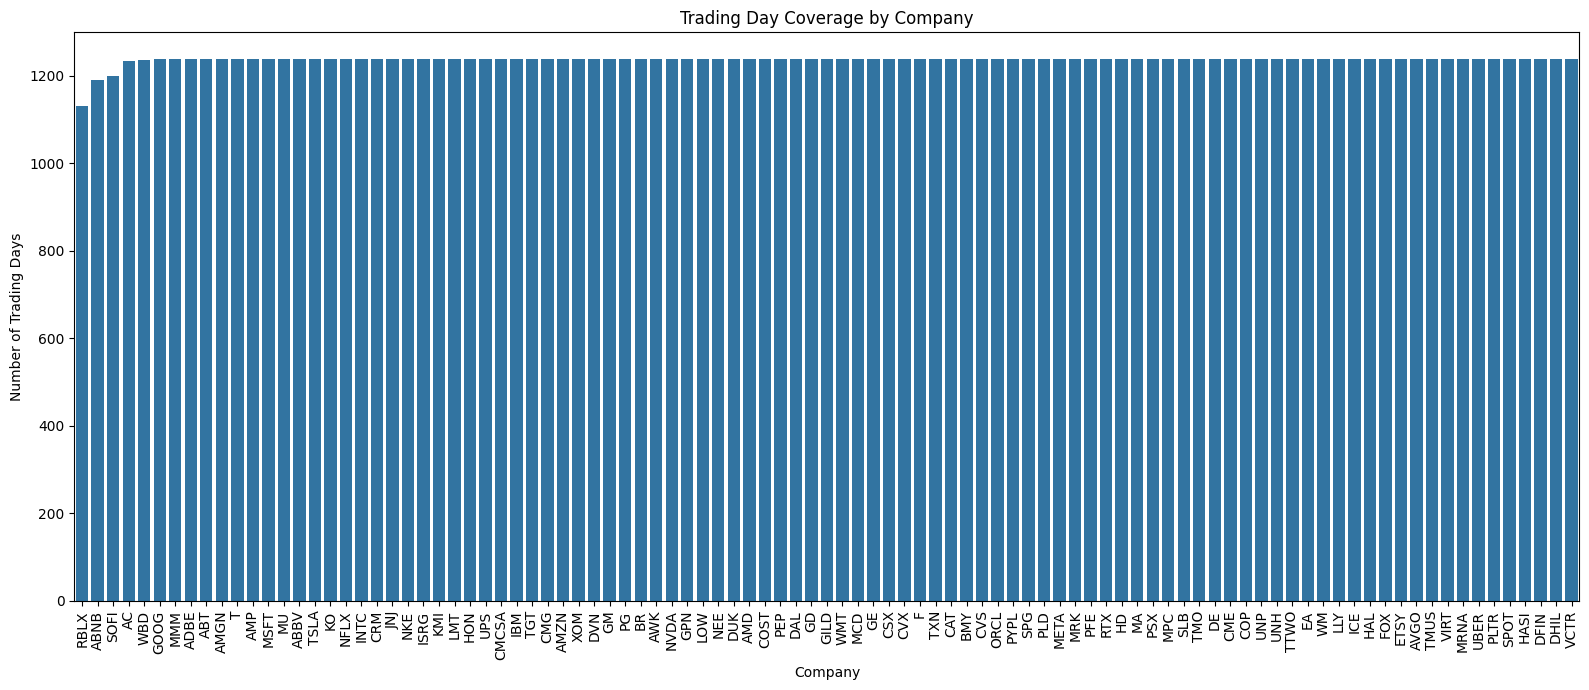

In [ ]:
plt.figure(figsize=(16,7))

sns.barplot(data=company_records.sort_values("Trading Days"), x="Ticker", y="Trading Days")

plt.title("Trading Day Coverage by Company")
plt.xlabel("Company")
plt.ylabel("Number of Trading Days")
plt.xticks(rotation=90)
plt.tight_layout()

plt.show()

### Interpretation

The bar plot confirms that the majority of selected companies have nearly complete trading histories, with most companies containing approximately 1,237 trading-day observations.

Three companies have noticeably fewer observations, with trading histories around 1,130–1,200 days. These reduced histories do not necessarily indicate data-quality problems and may be related to differences in the companies' market histories.

Overall, the trading-day coverage is highly consistent across the selected company universe.


In [ ]:
short_history = company_records[company_records["Trading Days"] < company_records["Trading Days"].max()].sort_values("Trading Days")

short_history

,SimFinId,Ticker,Trading Days
90,1338975,RBLX,1131
89,1214552,ABNB,1191
92,3307892,SOFI,1199
86,919941,AC,1234
30,120376,WBD,1235


## 10.2 Interpretation

The trading-day coverage shows that most selected companies have nearly complete historical market data, with the maximum coverage being **1,237 trading days**.

Five companies have fewer observations:

* **RBLX:** 1,131 trading days
* **ABNB:** 1,191 trading days
* **SOFI:** 1,199 trading days
* **AC:** 1,234 trading days
* **WBD:** 1,235 trading days

The reduced number of observations does not automatically indicate a data-quality problem. Companies may have shorter histories because they became publicly traded more recently or because of differences in their available market-data history.

Therefore, these companies will **not be removed at this stage**. Their historical coverage will be considered later when calculating time-dependent features and constructing the final machine-learning dataset.


## 10.3 Distribution of Adjusted Closing Prices

The adjusted closing price represents the historical closing price adjusted for events such as stock splits and dividends. It is particularly useful when analyzing investment performance and calculating historical returns.

A histogram is used to examine the distribution of adjusted closing prices across the selected companies and trading days.

This visualization helps identify the typical price ranges in the dataset and whether the distribution contains extreme values or strong skewness.


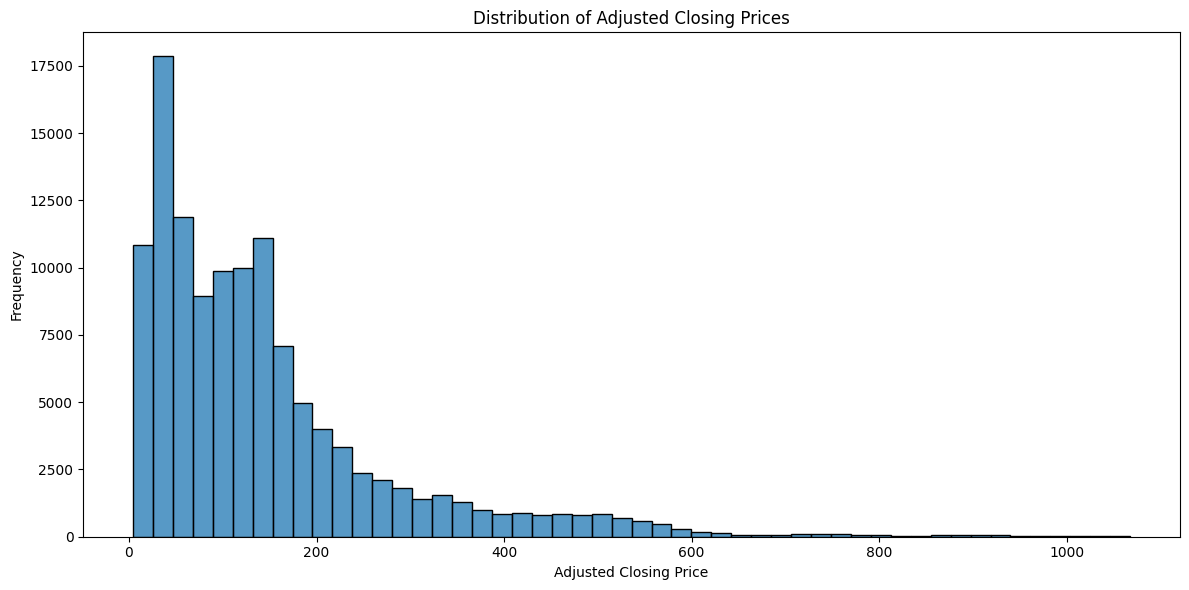

In [ ]:
plt.figure(figsize=(12,6))

sns.histplot(data=share_prices_selected, x="Adj. Close", bins=50)

plt.title("Distribution of Adjusted Closing Prices")
plt.xlabel("Adjusted Closing Price")
plt.ylabel("Frequency")
plt.tight_layout()

plt.show()

### 10.3.1 Interpretation

The histogram shows that the distribution of adjusted closing prices is **right-skewed**. Most observations are concentrated at relatively lower price values, while a smaller number of observations extend toward much higher prices, creating a long tail on the right.

This pattern is expected when combining stock-price observations from many different companies because companies can have very different share-price levels.

The long right tail does not necessarily indicate incorrect or anomalous data. A high stock price simply means that the company's shares trade at a higher nominal price.

Therefore, no observations will be removed based solely on the skewness of the adjusted closing-price distribution.

For machine-learning purposes, raw stock price levels will also be interpreted carefully because the price of one company's share is not directly comparable to another company's share price. **Returns and other normalized features will be more useful for comparing companies.**


## 10.4 Distribution of Trading Volume

Trading volume represents the number of shares traded during a trading session. It provides information about the level of market activity and liquidity associated with a stock.

A histogram is used to examine the distribution of daily trading volume across the selected companies.

This analysis helps identify the typical volume range and determine whether the data contains strong skewness or extreme observations. Understanding the distribution is also useful because trading volume may later be used as a market-related feature in the machine-learning dataset.


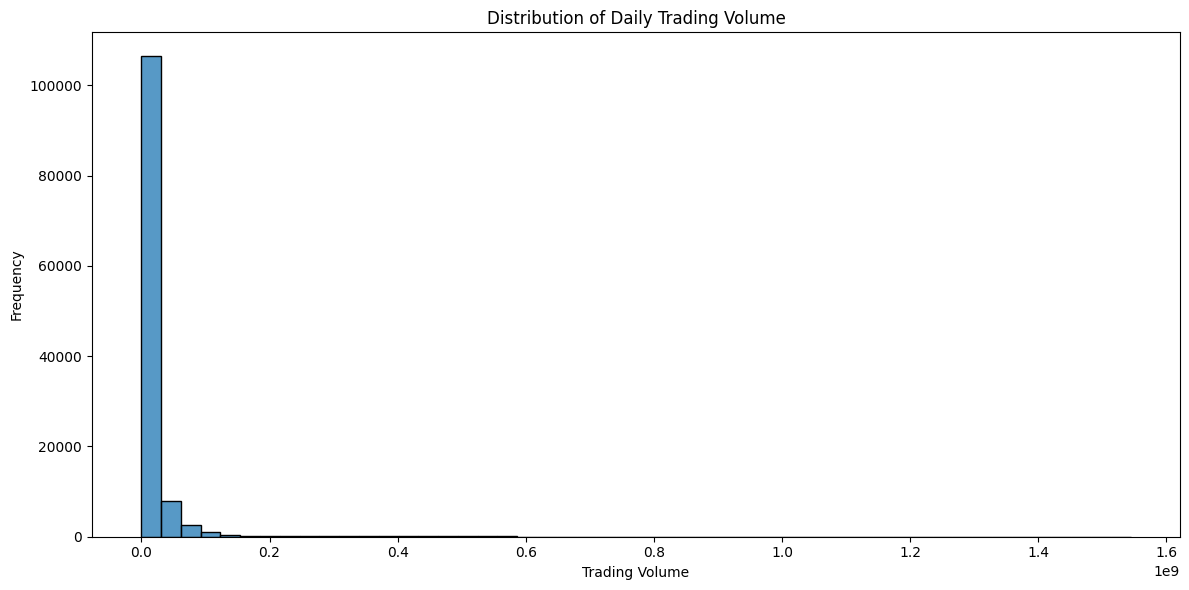

In [ ]:
plt.figure(figsize=(12,6))

sns.histplot(data=share_prices_selected, x="Volume", bins=50)

plt.title("Distribution of Daily Trading Volume")
plt.xlabel("Trading Volume")
plt.ylabel("Frequency")
plt.tight_layout()

plt.show()

### 10.4.1 Interpretation

The histogram shows that daily trading volume is **strongly right-skewed**. Most observations have relatively low trading volume, while a smaller number of observations have very high volumes, extending to approximately **600 million shares** in the observed data.

This pattern is expected because different companies have substantially different levels of market activity and liquidity. Large, actively traded companies can generate much higher daily trading volumes than smaller companies.

The extreme values are therefore not automatically considered errors. They represent genuine differences in trading activity between companies and trading sessions.

Because of this strong skewness, raw trading volume may not be ideal for direct comparison between companies. During feature engineering, we will consider an appropriate transformation or normalized representation of volume rather than automatically removing high-volume observations.

Trading volume will be retained in the working dataset because it may provide useful information about market activity and liquidity for the machine-learning model.


## 10.5 Correlation Between Numerical Market Variables

Correlation analysis is used to examine the strength and direction of linear relationships between numerical variables.

For the Share Prices dataset, we focus on the main market variables:

* `Open`
* `High`
* `Low`
* `Close`
* `Adj. Close`
* `Volume`

The `SimFinId` column is intentionally excluded because it is an identifier and its numerical value has no financial meaning.

A correlation heatmap provides a visual summary of these relationships. Correlation values range from **-1 to +1**:

* Values close to **+1** indicate a strong positive linear relationship.
* Values close to **-1** indicate a strong negative linear relationship.
* Values close to **0** indicate little or no linear relationship.

This analysis helps us understand the structure of the market data and identify variables that contain highly similar information.


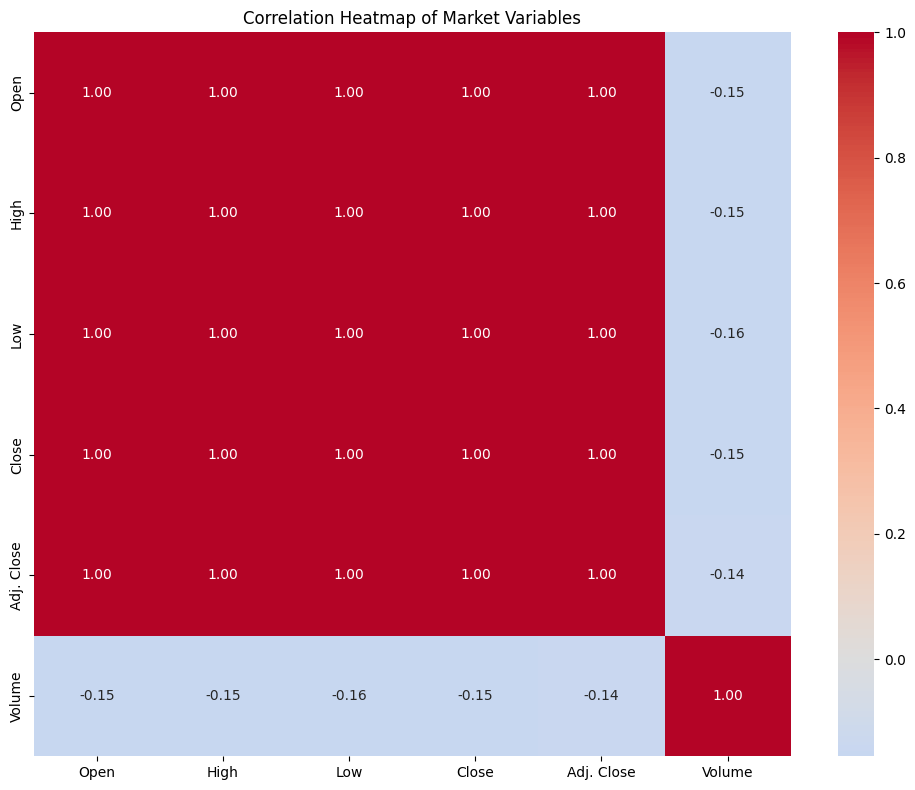

In [ ]:
correlation_columns = ["Open", "High", "Low", "Close", "Adj. Close", "Volume"]

correlation_matrix = (share_prices_selected[correlation_columns].corr())

plt.figure(figsize=(10,8))

sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0)

plt.title("Correlation Heatmap of Market Variables")
plt.tight_layout()

plt.show()

### 10.5.1 Interpretation

The correlation heatmap shows two clear patterns.

First, the price-related variables (`Open`, `High`, `Low`, `Close`, and `Adj. Close`) have very strong positive correlations, with values displayed as approximately **1.00**.

This is expected because these variables represent different price measurements from the same trading session. When the overall price level of a stock increases, its Open, High, Low, and Close prices generally increase together.

Second, `Volume` has weak negative correlations with the price variables, approximately between **-0.14 and -0.16**. This indicates that there is only a weak linear relationship between daily trading volume and the observed price levels across the combined dataset.

The heatmap therefore confirms that the OHLC price variables contain highly similar information, while trading volume behaves differently from the price variables.

However, **high correlation does not mean that one variable should automatically be removed**. The decision about which variables to use in the machine-learning model will be made later during feature engineering, based on the prediction objective and the information available at the prediction point.


## 10.6 Average Adjusted Closing Price by Company

The previous histogram showed the overall distribution of adjusted closing prices across all observations. However, this combines all 97 companies together.

To understand differences between companies, we calculate the mean `Adj. Close` for each company.

The resulting values represent the average nominal adjusted share price observed during the available historical period for each company. A bar plot is then used to compare these values across companies.

This analysis is intended to demonstrate the differences in nominal share-price levels between companies. It should not be interpreted as a measure of company value or investment attractiveness.


In [ ]:
average_price = (share_prices_selected.groupby("Ticker")["Adj. Close"]
                                      .mean()
                                      .sort_values()
                                      .reset_index()
                                      )

average_price.head()

,Ticker,Adj. Close
0,F,10.119830
1,SOFI,11.262627
2,KMI,16.445748
3,T,16.857680
4,WBD,17.532834


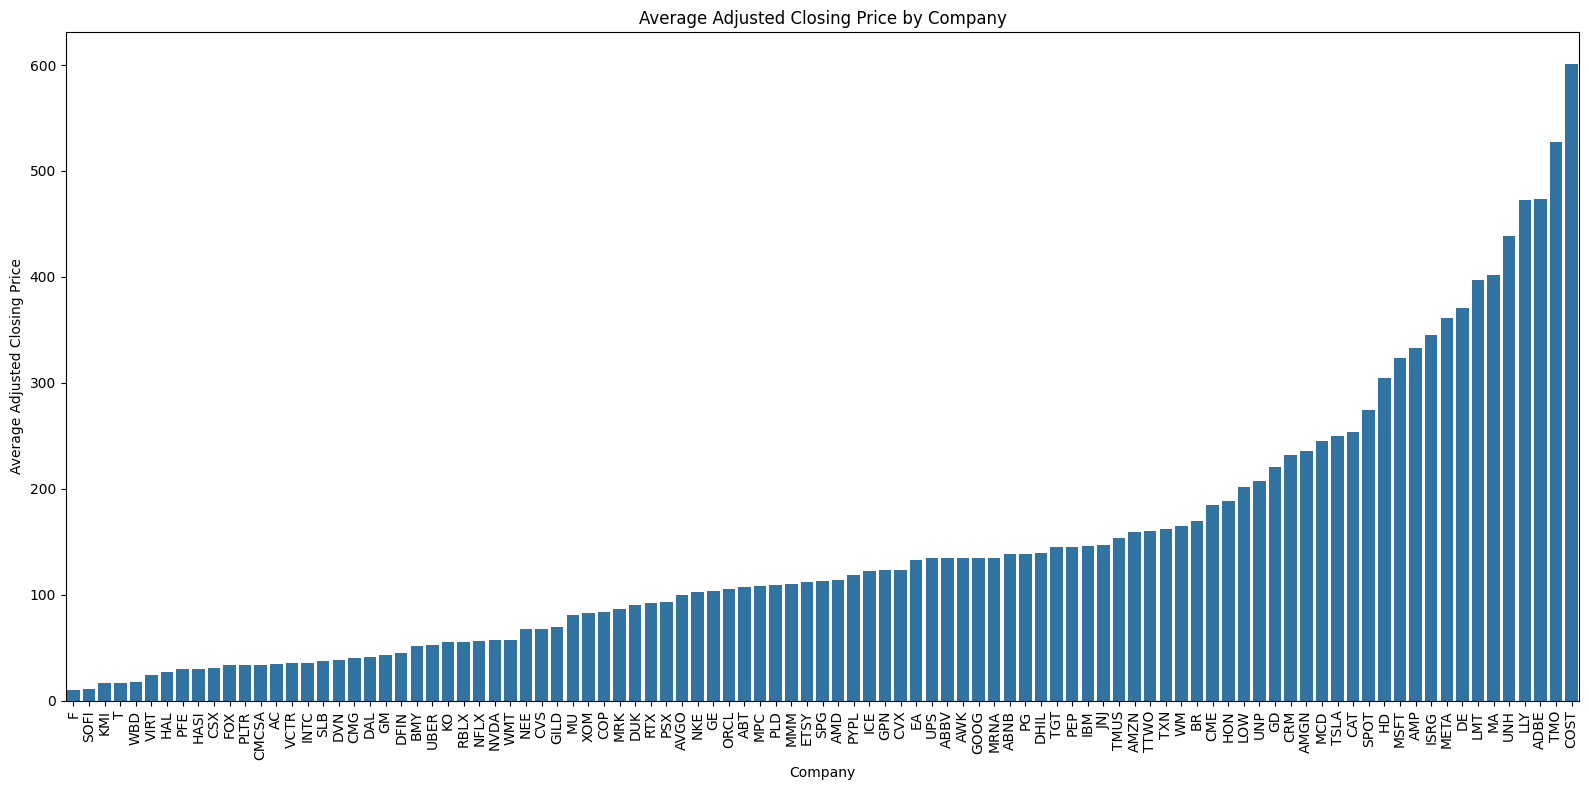

In [ ]:
plt.figure(figsize=(16, 8))

sns.barplot(data=average_price, x="Ticker", y="Adj. Close")

plt.title("Average Adjusted Closing Price by Company")
plt.xlabel("Company")
plt.ylabel("Average Adjusted Closing Price")
plt.xticks(rotation=90)
plt.tight_layout()

plt.show()

### 10.6.2 Interpretation

The bar plot shows substantial differences in the average adjusted closing prices across the selected companies.

Most companies have relatively lower average share prices, while a smaller number of companies have considerably higher average prices, with some exceeding approximately **$550–$600** during the observed period.

These differences represent **nominal share-price levels** and should not be interpreted as differences in company size, value, or investment quality. A company's share price depends partly on factors such as its number of outstanding shares and stock-split history.

The visualization reinforces why raw share price should be treated carefully when comparing companies. For machine-learning purposes, normalized measures such as **returns and volatility** are generally more informative for comparing investment performance across different companies.


## 10.7 Average Trading Volume by Company

Average daily trading volume provides an indication of how actively a company's shares are traded in the market.

Companies with higher trading volumes generally exhibit greater market liquidity, while companies with lower trading volumes tend to trade less frequently.

To compare trading activity across the selected companies, the average daily trading volume is calculated for each company and visualized using a bar chart.


In [ ]:
average_volume = (share_prices_selected.groupby("Ticker")["Volume"]
                                      .mean()
                                      .sort_values()
                                      .reset_index()
                                      )

print(average_volume.head())
average_volume.tail()

  Ticker         Volume
0     AC    8699.090762
1   DHIL   14591.618432
2   DFIN  221106.320129
3   VCTR  284932.044462
4     BR  537384.831851


,Ticker,Volume
92,AMZN,5.983957e+07
93,AMD,6.096384e+07
94,F,6.987701e+07
95,TSLA,1.020566e+08
96,NVDA,4.041861e+08


### 10.7.1 Average Trading Volume by Company

The calculated average daily trading volume for each company is visualized using a bar chart.

This visualization highlights differences in market activity across the selected companies and helps identify highly liquid and less frequently traded stocks within the dataset.


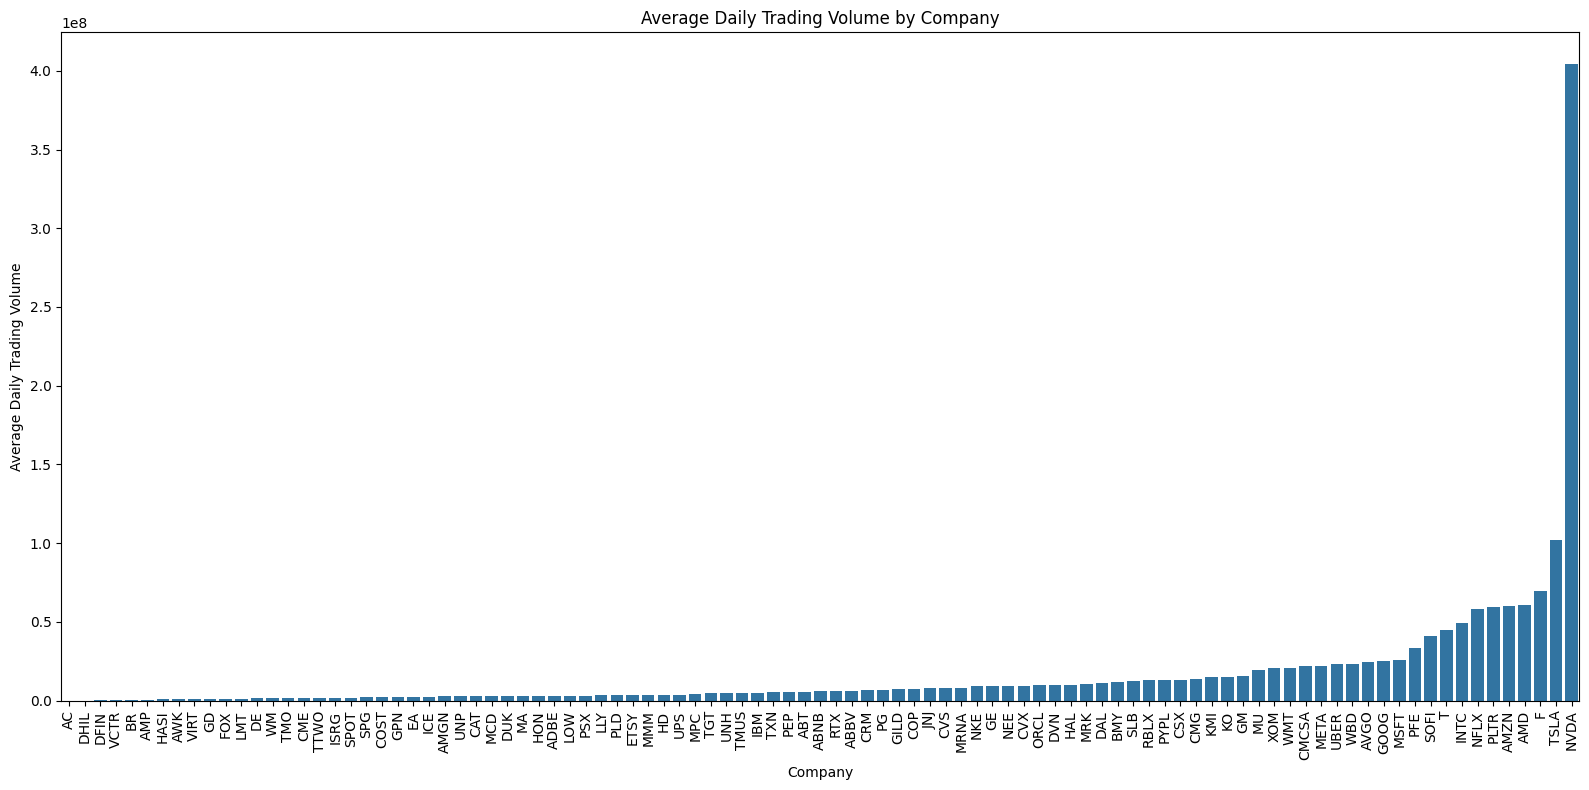

In [ ]:
plt.figure(figsize=(16,8))

sns.barplot(data=average_volume, x="Ticker", y="Volume")

plt.title("Average Daily Trading Volume by Company")
plt.xlabel("Company")
plt.ylabel("Average Daily Trading Volume")
plt.xticks(rotation=90)
plt.tight_layout()

plt.show()


### 10.7.2 Interpretation

The bar plot reveals substantial variation in average daily trading volume across the selected companies.

Most companies have relatively modest average trading volumes, while a small number of companies exhibit exceptionally high trading activity. In particular, **NVIDIA** has the highest average daily trading volume, standing well above the majority of other companies.

This produces a **right-skewed distribution**, where most companies are concentrated at lower volume levels and only a few companies contribute to the long right tail.

The differences are expected because companies vary considerably in market capitalization, investor interest, and liquidity. Therefore, large trading volumes should not be treated as data errors but as genuine characteristics of highly traded stocks.

These findings suggest that raw trading volume spans a wide numerical range. During feature engineering, appropriate normalization or transformation may improve its suitability as a machine-learning feature.


## 10.8 Boxplot Analysis

Boxplots provide a compact summary of a numerical variable by displaying its median, quartiles, overall spread, and potential outliers.

Unlike histograms, which emphasize the shape of a distribution, boxplots make it easier to identify unusually large or small observations.

For the Share Prices dataset, boxplots are created for both **Adjusted Closing Price** and **Trading Volume** to examine the variability of these market variables and to identify potential extreme values.


### 10.8.1 Adjusted Closing Price

The following boxplot summarizes the distribution of adjusted closing prices across all observations in the dataset.

The visualization highlights the median price, the interquartile range (IQR), and observations that fall beyond the typical range of the data.


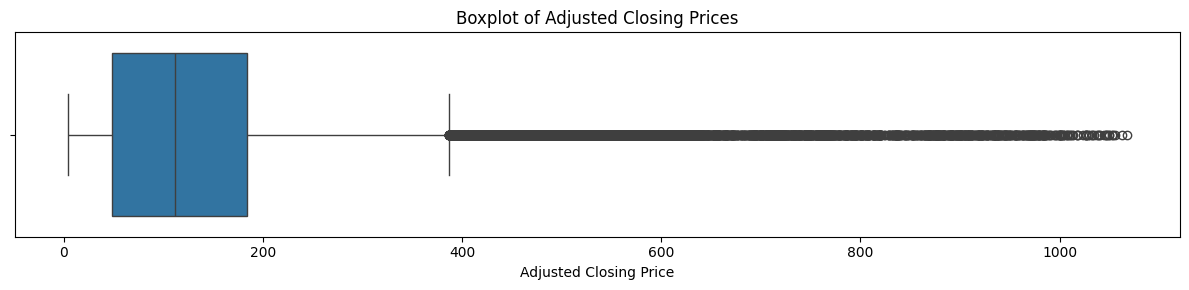

In [ ]:
plt.figure(figsize=(12, 3))

sns.boxplot(x=share_prices_selected["Adj. Close"])

plt.title("Boxplot of Adjusted Closing Prices")
plt.xlabel("Adjusted Closing Price")
plt.tight_layout()

plt.show()

### 10.8.2 Trading Volume

The following boxplot summarizes the distribution of daily trading volume.

This visualization is particularly useful because trading volume often contains substantial variation between companies and may exhibit numerous high-value observations.


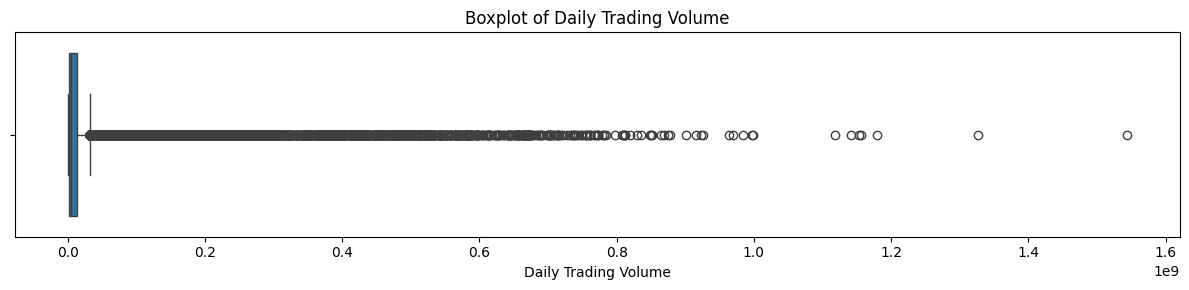

In [ ]:
plt.figure(figsize=(12, 3))

sns.boxplot(x=share_prices_selected["Volume"])

plt.title("Boxplot of Daily Trading Volume")
plt.xlabel("Daily Trading Volume")
plt.tight_layout()

plt.show()

### 10.8.3 Interpretation

The boxplots provide additional evidence of substantial variation in both adjusted closing prices and trading volume.

For adjusted closing prices, the majority of observations are concentrated within a relatively narrow range, while a large number of observations appear beyond the upper whisker. These observations represent higher-priced stocks within the combined dataset and should not automatically be considered erroneous.

The trading-volume boxplot also identifies a small number of observations with exceptionally high trading volume. These extreme observations may correspond to periods of unusually high market activity and therefore should not be removed solely because they are classified as statistical outliers.

Overall, the boxplots confirm that both variables are highly variable and right-skewed. Rather than removing these observations, the underlying market characteristics will be considered during feature engineering. In particular, normalized or transformed measures may be more appropriate than raw price and volume values for machine-learning models.


## 10.9 Time-Series Analysis

Time-series analysis examines how market variables change over time.

For this project, understanding historical price movements is important because later feature engineering will derive time-dependent variables such as historical returns and volatility.

Rather than plotting all 97 companies simultaneously, three representative companies are selected to make the visualization easier to interpret. Adjusted closing prices are used because they account for historical corporate actions such as stock splits and dividends.


In [ ]:
selected_tickers = ["AMZN", "NVDA", "SOFI"]

time_series_data = share_prices_selected[share_prices_selected["Ticker"].isin(selected_tickers)].copy()

time_series_data = time_series_data.sort_values("Date")

time_series_data.head()

,Ticker,SimFinId,Date,Open,High,Low,Close,Adj. Close,Volume,Dividend,Shares Outstanding
337279,AMZN,62747,2020-10-06,158.25,159.10,154.50,155.00,155.00,101737140,NaN,1.004000e+10
3983205,NVDA,172199,2020-10-06,13.83,14.14,13.66,13.74,13.68,784419840,NaN,2.468000e+10
3983206,NVDA,172199,2020-10-07,14.00,14.12,13.86,13.96,13.90,418085160,NaN,2.468000e+10
337280,AMZN,62747,2020-10-07,156.75,160.00,156.62,159.78,159.78,86188780,NaN,1.004000e+10
3983207,NVDA,172199,2020-10-08,14.07,14.08,13.76,13.84,13.78,378900880,NaN,2.468000e+10


### 10.9.1 Adjusted Closing Price Over Time

The adjusted closing prices of the three selected companies are plotted over time to examine their historical price movements.

A line chart is appropriate for this analysis because the observations are ordered chronologically. The visualization allows us to observe trends, periods of rapid price changes, and differences in historical price behavior between companies.


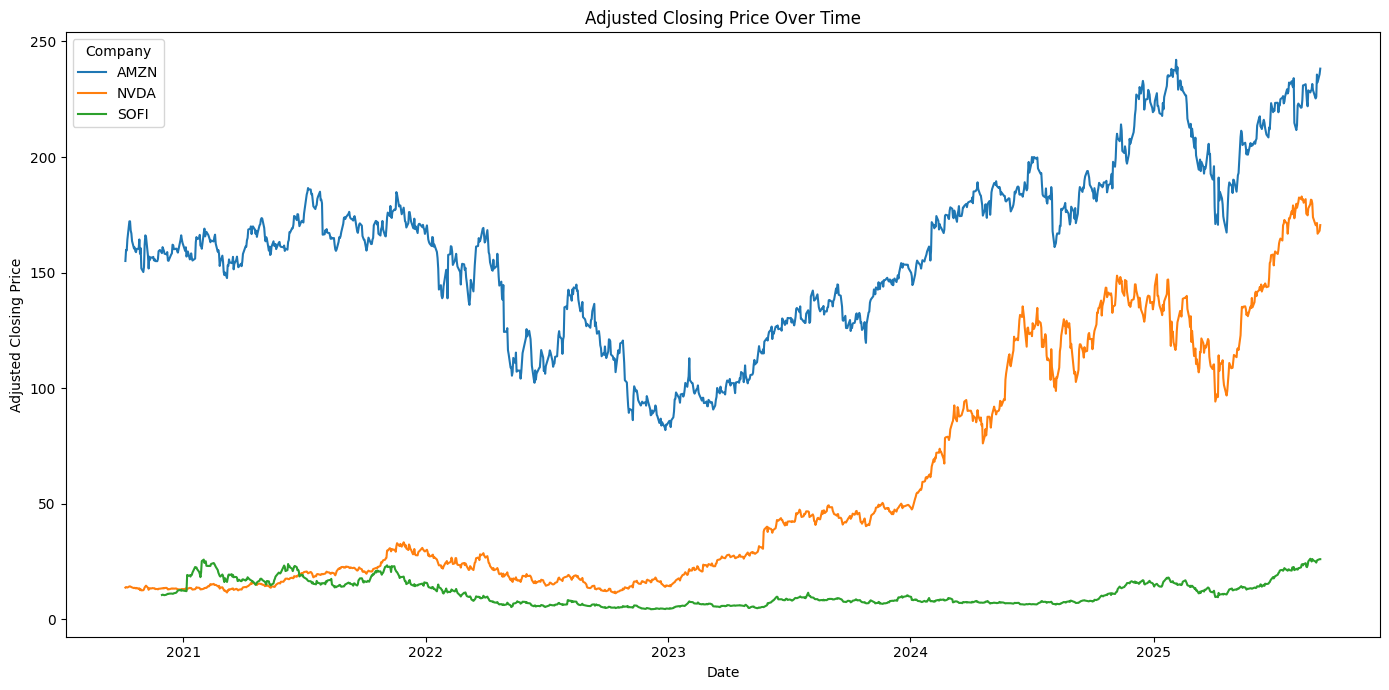

In [ ]:
plt.figure(figsize=(14, 7))

sns.lineplot(data=time_series_data, x="Date", y="Adj. Close", hue="Ticker")

plt.title("Adjusted Closing Price Over Time")
plt.xlabel("Date")
plt.ylabel("Adjusted Closing Price")
plt.legend(title="Company")
plt.tight_layout()

plt.show()

In [ ]:
time_series_data.groupby("Ticker")["Adj. Close"].agg(["min", "max"])

,min,max
Ticker,,
AMZN,81.82,242.06
NVDA,11.20,182.92
SOFI,4.30,26.15


In [ ]:
selected_comp[selected_comp["Ticker"].astype(str).str.contains("AAP", case=False, na=False)
]

,Company,SimFinId,Ticker


In [ ]:
aapl_id = selected_comp.loc[selected_comp["Ticker"] == "AAPL", "SimFinId"].iloc[0]

print("AAPL SimFinId:", aapl_id)

IndexError: single positional indexer is out-of-bounds

### 10.9.2 Interpretation

The time-series visualization shows that the selected companies have substantially different adjusted share-price levels and historical price movements.

AMZN displays a considerably higher nominal adjusted share price than NVDA and SOFI during parts of the observed period. NVDA shows relatively moderate price movement during the earlier years followed by a pronounced increase beginning around 2024, while SOFI exhibits a strong increase around 2021 followed by a decline and subsequent recovery.

The differences in nominal share-price levels demonstrate why raw stock prices should not be used directly to compare investment performance across companies. A higher share price does not necessarily indicate a larger or more valuable company because share price is also affected by the number of shares outstanding and corporate actions such as stock splits.

For the machine-learning stage, normalized and time-dependent measures such as historical returns and volatility will therefore be more informative than raw share-price levels.


## 10.10 Exploratory Data Analysis Summary

The exploratory analysis was conducted to understand the structure, coverage, distributions, relationships, and temporal behavior of the selected companies' historical market data.

### Main Findings

**Trading history:**
The filtered Share Prices dataset contains **97 of the 100 selected companies**, with a maximum of **1,237 trading-day observations** per company. Five companies have shorter histories, with RBLX having the fewest observations at 1,131 trading days. These differences were retained because shorter histories do not necessarily indicate erroneous data.

**Price distributions:**
Adjusted closing prices are strongly right-skewed. The combined dataset contains companies with substantially different nominal share-price levels. Therefore, raw share prices are not directly comparable across companies and will not be treated as a direct measure of investment performance.

**Trading volume:**
Daily trading volume is also strongly right-skewed. A small number of companies and trading sessions have exceptionally high trading activity. These observations were retained because extreme volume can represent genuine market activity rather than erroneous data.

**Correlation:**
The OHLC price variables show very strong positive correlations because they represent different price measurements from the same trading session. Trading volume has only a weak linear relationship with the price variables.

**Outliers:**
The boxplots identified observations with unusually high adjusted prices and trading volumes. These observations were not automatically removed because statistical outliers are not necessarily data errors.

**Time-series behavior:**
The selected companies exhibit substantially different historical price patterns. Some companies show strong increases or decreases during particular periods, while others have shorter or more volatile histories. The time-series analysis further demonstrates why normalized measures such as returns are more appropriate for comparing companies.

### Overall Conclusion

The Share Prices dataset has sufficient quality and historical coverage for the next stage of the project. Core market variables contain no missing values, duplicate company-date records were not identified, and all tested OHLC and price/volume validity rules passed successfully.

The EDA indicates that raw price and volume variables have highly different scales and skewed distributions. These characteristics will be taken into account during feature engineering.

The next stage will transform the historical market data into meaningful features that can be aligned with financial reporting information while ensuring that only information available at the prediction point is used.


# 11. Feature Engineering

## 11.1 Feature Engineering Strategy

Feature engineering transforms the cleaned financial and market data into meaningful variables that can be used by the machine learning model.

The features are designed to represent three main aspects of a company:

* **Historical market performance** — how the stock has performed in the past.
* **Market risk and activity** — how much the stock price has fluctuated and how actively it has been traded.
* **Financial performance and company characteristics** — the company's growth, profitability, liquidity, leverage, cash generation, sector, and industry.

For market-based features, calculations are made using information available at or before the prediction point $(t_0)$. The prediction point is defined as the first available trading day on or after the company's financial information **Publish Date**.

The feature-engineering process is designed to avoid **look-ahead bias**. Information from after $(t_0)$, including future stock prices, is not used as an input feature. Future stock-price information is reserved exclusively for constructing the target variable.

The main engineered features include historical stock return, historical volatility, average trading volume, financial growth and profitability measures, liquidity and leverage measures, free cash flow measures, and categorical sector and industry information.

The final target variable will represent whether the company achieves a **positive 1-year future stock return** after $(t_0)$.


**Inspecting Raw Income Statement Dataset**

In [ ]:
print("Shape of Income Statement:", df_income.shape)

print("\nColumns:",df_income.columns.tolist())

print("\n First 5 rows:", df_income.head())

print("\nData Types:", df_income.dtypes)

print("\nMissing Values:", df_income.isna().sum())

df_income[["SimFinId", "Ticker", "Report Date", "Publish Date"]].head(10)


Shape of Income Statement: (16844, 28)

Columns: ['Ticker', 'SimFinId', 'Currency', 'Fiscal Year', 'Fiscal Period', 'Report Date', 'Publish Date', 'Restated Date', 'Shares (Basic)', 'Shares (Diluted)', 'Revenue', 'Cost of Revenue', 'Gross Profit', 'Operating Expenses', 'Selling, General & Administrative', 'Research & Development', 'Depreciation & Amortization', 'Operating Income (Loss)', 'Non-Operating Income (Loss)', 'Interest Expense, Net', 'Pretax Income (Loss), Adj.', 'Abnormal Gains (Losses)', 'Pretax Income (Loss)', 'Income Tax (Expense) Benefit, Net', 'Income (Loss) from Continuing Operations', 'Net Extraordinary Gains (Losses)', 'Net Income', 'Net Income (Common)']

 First 5 rows:   Ticker  SimFinId Currency  Fiscal Year Fiscal Period Report Date  \
0      A     45846      USD         2020            FY  2020-10-31   
1      A     45846      USD         2021            FY  2021-10-31   
2      A     45846      USD         2022            FY  2022-10-31   
3      A     45846    

,SimFinId,Ticker,Report Date,Publish Date
0,45846,A,2020-10-31,2020-12-18
1,45846,A,2021-10-31,2021-12-17
2,45846,A,2022-10-31,2022-12-21
3,45846,A,2023-10-31,2023-12-20
4,45846,A,2024-10-31,2024-12-20
5,1333027,A21,2020-12-31,2021-03-10
6,1333027,A21,2021-12-31,2022-04-19
7,367153,AA,2020-12-31,2021-02-25
8,367153,AA,2021-12-31,2022-02-24
9,367153,AA,2022-12-31,2023-02-23


### 11.2.1 Selecting the Target Companies

The raw SimFin Income Statement contains financial records for many companies. Since the project focuses on a predefined set of 100 selected companies, the dataset is filtered using `SimFinId` as the primary company identifier.

Using `SimFinId` ensures that companies are matched reliably without depending on company names or ticker symbols.


In [ ]:
income_st_selected = df_income[df_income["SimFinId"].isin(selected_ids)].copy()

print("Filtered Income Statement Shape:", income_st_selected.shape)

Filtered Income Statement Shape: (500, 28)


In [ ]:
income_st_ids = income_st_selected["SimFinId"].unique()

print("Selected companies:", len(selected_ids))
print("Companies in Income Statement:", len(income_st_ids))

Selected companies: 100
Companies in Income Statement: 100


In [ ]:
income_records = (income_st_selected.groupby(["SimFinId", "Ticker"])
                                          .size()
                                          .reset_index(name="Financial Records")
)

income_records["Financial Records"].value_counts().sort_index()

,count
Financial Records,
5,100


In [ ]:
income_st_selected[["SimFinId", "Ticker", "Fiscal Year", "Fiscal Period", "Report Date", "Publish Date"]
].sort_values(["SimFinId", "Fiscal Year"]).head(20)

,SimFinId,Ticker,Fiscal Year,Fiscal Period,Report Date,Publish Date
6611,18,GOOG,2020,FY,2020-12-31,2021-02-03
6612,18,GOOG,2021,FY,2021-12-31,2022-02-02
6613,18,GOOG,2022,FY,2022-12-31,2023-02-03
6614,18,GOOG,2023,FY,2023-12-31,2024-01-31
6615,18,GOOG,2024,FY,2024-12-31,2025-02-05
279,14099,ADBE,2020,FY,2020-11-30,2021-01-15
280,14099,ADBE,2021,FY,2021-11-30,2022-01-21
281,14099,ADBE,2022,FY,2022-11-30,2023-01-17
282,14099,ADBE,2023,FY,2023-11-30,2024-01-17
283,14099,ADBE,2024,FY,2024-11-30,2025-01-13


### 11.2.2 Converting Date Columns

The `Report Date`, `Publish Date`, and `Restated Date` columns are initially stored as objects because the data was loaded from CSV. These columns are converted to Pandas datetime format to enable accurate date comparisons and time-based feature engineering.

`Publish Date` is particularly important because it will be used to determine the prediction point $(t_0)$.


In [ ]:
date_columns = ["Report Date", "Publish Date", "Restated Date"]

for column in date_columns:
  income_st_selected[column] = pd.to_datetime(income_st_selected[column])

print(income_st_selected[date_columns].dtypes)

Report Date      datetime64[ns]
Publish Date     datetime64[ns]
Restated Date    datetime64[ns]
dtype: object


### 11.2.3 Determining the Prediction Point \(t_0\)

The prediction point is defined as the first available trading day on or after the financial information's Publish Date. This ensures that the financial information used by the model was publicly available when the market observation was recorded.

We will match each financial observation to the Share Prices dataset using SimFinId and date information.

For example:

Publish Date → first available trading date on/after Publish Date → t₀

We'll now perform that matching.

### 11.2.4 Preparing Data for $(t_0)$ Matching

To determine $(t_0)$, we need to connect each financial observation to the first available trading day on or after its `Publish Date`.

We create two temporary DataFrames:

- A financial timeline containing the company identifier, fiscal year, and `Publish Date`.
- A price timeline containing the company identifier, trading date, and adjusted closing price.

The company is identified using `SimFinId`, which allows the financial and market datasets to be matched reliably.

In [ ]:
financial_timeline = income_st_selected[["SimFinId", "Ticker", "Fiscal Year", "Publish Date"]].copy()

price_timeline = share_prices_selected[["SimFinId", "Date", "Adj. Close"]].copy()

financial_timeline = financial_timeline.sort_values(["Publish Date", "SimFinId"]).reset_index(drop=True)

price_timeline = price_timeline.sort_values(["Date", "SimFinId"]).reset_index(drop=True)

print("Financial timeline:")
display(financial_timeline.head())

print("\nPrice timeline:")
display(price_timeline.head())

Financial timeline:


,SimFinId,Ticker,Fiscal Year,Publish Date
0,686523,AVGO,2020,2020-11-18
1,373449,DE,2020,2020-12-17
2,14099,ADBE,2020,2021-01-15
3,85652,INTC,2020,2021-01-22
4,353500,SLB,2020,2021-01-27



Price timeline:


,SimFinId,Date,Adj. Close
0,18,2020-10-06,72.03
1,14099,2020-10-06,478.98
2,22219,2020-10-06,111.27
3,56317,2020-10-06,137.99
4,59265,2020-10-06,195.80


In [ ]:
# Find t0
t0_data = pd.merge_asof(financial_timeline, price_timeline,
                        left_on="Publish Date", right_on="Date",
                        by="SimFinId",
                        direction="forward"
                        )

t0_data.head()

,SimFinId,Ticker,Fiscal Year,Publish Date,Date,Adj. Close
0,686523,AVGO,2020,2020-11-18,2020-11-18,33.84
1,373449,DE,2020,2020-12-17,2020-12-17,245.77
2,14099,ADBE,2020,2021-01-15,2021-01-15,458.08
3,85652,INTC,2020,2021-01-22,2021-01-22,51.22
4,353500,SLB,2020,2021-01-27,2021-01-27,19.18


In [ ]:
# Validation check
print("Total financial records:", len(t0_data))
print("\nRecords with missing t₀:", t0_data["Date"].isna().sum())

Total financial records: 500

Records with missing t₀: 17


In [ ]:
# Inspect the missing t0
t0_data[t0_data["Date"].isna()][["SimFinId", "Ticker", "Fiscal Year", "Publish Date"]]

,SimFinId,Ticker,Fiscal Year,Publish Date
74,628032,OAK,2020,2021-02-26
78,286372,DLR,2020,2021-03-01
92,73420,MDT,2021,2021-06-25
172,286372,DLR,2021,2022-02-25
182,628032,OAK,2021,2022-03-14
192,73420,MDT,2022,2022-06-23
276,286372,DLR,2022,2023-02-27
287,628032,OAK,2022,2023-03-21
292,73420,MDT,2023,2023-06-22
369,286372,DLR,2023,2024-02-23


In [ ]:
# Remove the rows with missing \(t_0\) from working DataFrame
t0_data = t0_data.dropna(subset=["Date"]).copy()

print("Records after removing missing t₀:", len(t0_data))
print("Remaining companies:", t0_data["SimFinId"].nunique())

Records after removing missing t₀: 483
Remaining companies: 97


In [ ]:
#Rename "Date" column to t0
t0_data = t0_data.rename(columns={"Date": "t0", "Adj. Close": "Price at t0"})

t0_data.head()

,SimFinId,Ticker,Fiscal Year,Publish Date,t0,Price at t0
0,686523,AVGO,2020,2020-11-18,2020-11-18,33.84
1,373449,DE,2020,2020-12-17,2020-12-17,245.77
2,14099,ADBE,2020,2021-01-15,2021-01-15,458.08
3,85652,INTC,2020,2021-01-22,2021-01-22,51.22
4,353500,SLB,2020,2021-01-27,2021-01-27,19.18


### 11.2.5 Determining the One-Year Reference Date

For each prediction point $(t_0)$, we calculate the calendar date exactly one year later.

This date is used as the reference point for locating $(t_1)$, the first available trading day on or after the one-year anniversary.

The one-year reference date is not necessarily a trading day.

In [ ]:
t0_data["One Year Date"] = t0_data["t0"] + pd.DateOffset(years=1)

t0_data[["SimFinId", "Ticker", "t0", "One Year Date"]].head()

,SimFinId,Ticker,t0,One Year Date
0,686523,AVGO,2020-11-18,2021-11-18
1,373449,DE,2020-12-17,2021-12-17
2,14099,ADBE,2021-01-15,2022-01-15
3,85652,INTC,2021-01-22,2022-01-22
4,353500,SLB,2021-01-27,2022-01-27


In [ ]:
# Sort by date column and then Find t1
t0_data = t0_data.sort_values(["One Year Date", "SimFinId"]).reset_index(drop=True)

price_timeline = price_timeline.sort_values(["Date", "SimFinId"]).reset_index(drop=True)

t1_data = pd.merge_asof(t0_data, price_timeline,
                        left_on="One Year Date", right_on="Date",
                        by="SimFinId",
                        direction="forward"
                        )

t1_data = t1_data.rename(columns={"Date": "t1", "Adj. Close": "Price at t1"})

t1_data[["SimFinId", "Ticker", "t0", "Price at t0", "One Year Date", "t1", "Price at t1"]].head()

,SimFinId,Ticker,t0,Price at t0,One Year Date,t1,Price at t1
0,686523,AVGO,2020-11-18,33.84,2021-11-18,2021-11-18,52.71
1,373449,DE,2020-12-17,245.77,2021-12-17,2021-12-17,325.93
2,14099,ADBE,2021-01-15,458.08,2022-01-15,2022-01-18,513.34
3,85652,INTC,2021-01-22,51.22,2022-01-22,2022-01-24,48.15
4,353500,SLB,2021-01-27,19.18,2022-01-27,2022-01-27,34.94


In [ ]:
# t1 Validation Check
print("Total observations:", len(t1_data))
print("\nObservations with missing t₁:", t1_data["t1"].isna().sum())

Total observations: 483

Observations with missing t₁: 97


In [ ]:
missing_t1 = t1_data[t1_data["t1"].isna()]

missing_t1[["SimFinId", "Ticker", "Fiscal Year", "Publish Date", "t0", "One Year Date"]].head(20)

,SimFinId,Ticker,Fiscal Year,Publish Date,t0,One Year Date
386,60906,MU,2024,2024-10-04,2024-10-04,2025-10-04
387,217867,COST,2024,2024-10-09,2024-10-09,2025-10-09
388,373449,DE,2024,2024-12-12,2024-12-12,2025-12-12
389,686523,AVGO,2024,2024-12-20,2024-12-20,2025-12-20
390,14099,ADBE,2024,2025-01-13,2025-01-13,2026-01-13
391,353500,SLB,2024,2025-01-22,2025-01-22,2026-01-22
392,83548,NFLX,2024,2025-01-27,2025-01-27,2026-01-27
393,103644,LMT,2024,2025-01-28,2025-01-28,2026-01-28
394,125620,GM,2024,2025-01-28,2025-01-28,2026-01-28
395,56317,TSLA,2024,2025-01-30,2025-01-30,2026-01-30


In [ ]:
t1_data[["SimFinId", "Ticker", "Fiscal Year", "Publish Date",
     "t0", "One Year Date", "t1", "Price at t1"]
].tail(20)

,SimFinId,Ticker,Fiscal Year,Publish Date,t0,One Year Date,t1,Price at t1
463,262090,PFE,2024,2025-02-27,2025-02-27,2026-02-27,NaT,NaN
464,353184,MPC,2024,2025-02-27,2025-02-27,2026-02-27,NaT,NaN
465,367714,UNH,2024,2025-02-27,2025-02-27,2026-02-27,NaT,NaN
466,378116,CME,2024,2025-02-27,2025-02-27,2026-02-27,NaT,NaN
467,239284,GILD,2024,2025-02-28,2025-02-28,2026-02-28,NaT,NaN
468,10384115,VCTR,2024,2025-02-28,2025-02-28,2026-02-28,NaT,NaN
469,85017,CRM,2024,2025-03-05,2025-03-05,2026-03-05,NaT,NaN
470,72458,TGT,2024,2025-03-12,2025-03-12,2026-03-12,NaT,NaN
471,239962,WMT,2024,2025-03-14,2025-03-14,2026-03-14,NaT,NaN
472,919941,AC,2024,2025-03-19,2025-03-19,2026-03-19,NaT,NaN


In [ ]:
print("Observations with valid t₁:", t1_data["t1"].notna().sum())
print("Observations without valid t₁:", t1_data["t1"].isna().sum())

Observations with valid t₁: 386
Observations without valid t₁: 97


### 11.2.6 Calculating the Future 1-Year Return

The future 1-year return measures the stock's price change between the prediction point $(t_0)$ and the first available trading day on or after the one-year anniversary $(t_1)$.

$$
\text{Future Return} = \frac{\text{Price at } t_1 - \text{Price at } t_0}{\text{Price at } t_0}
$$

This value is calculated only for observations with a valid $(t_1)$.

The future return is used exclusively to construct the target variable. It is not used as an input feature, because it represents information that was not available at the prediction point.

In [ ]:
valid_t1 = t1_data.dropna(subset=["t1"]).copy()

valid_t1["Future Return"] = ((valid_t1["Price at t1"] - valid_t1["Price at t0"]) / valid_t1["Price at t0"])

valid_t1[["SimFinId", "Ticker", "t0", "Price at t0", "t1", "Price at t1", "Future Return"]].head()

,SimFinId,Ticker,t0,Price at t0,t1,Price at t1,Future Return
0,686523,AVGO,2020-11-18,33.84,2021-11-18,52.71,0.557624
1,373449,DE,2020-12-17,245.77,2021-12-17,325.93,0.326159
2,14099,ADBE,2021-01-15,458.08,2022-01-18,513.34,0.120634
3,85652,INTC,2021-01-22,51.22,2022-01-24,48.15,-0.059938
4,353500,SLB,2021-01-27,19.18,2022-01-27,34.94,0.821689


**Save to outputs/market_features/**

In [ ]:
valid_t1.to_csv("/content/drive/MyDrive/data_handling_and_machine_learning/week_03/outputs/market_features/target_dataset.csv", index=False)

### 11.2.7 Creating the Binary Target

The machine learning model will predict whether a company achieves a positive stock return over the following one-year period.

The continuous `Future Return` is converted into a binary target:

$$
Target =
\begin{cases}
1 & \text{if Future Return} > 0\\
0 & \text{if Future Return} \leq 0
\end{cases}
$$

Therefore:

- `1` = positive 1-year future stock return
- `0` = non-positive 1-year future stock return

The future return and target are constructed using information after $(t_0)$. They are therefore target variables and must not be included as input features.

In [ ]:
valid_t1["Target"] = (valid_t1["Future Return"] > 0).astype(int)

valid_t1[["Ticker", "Future Return", "Target"]].head(10)

,Ticker,Future Return,Target
0,AVGO,0.557624,1
1,DE,0.326159,1
2,ADBE,0.120634,1
3,INTC,-0.059938,0
4,SLB,0.821689,1
5,NFLX,-0.286298,0
6,LMT,0.235632,1
7,META,0.138551,1
8,AMD,0.334073,1
9,GOOG,0.378302,1


In [ ]:
target_distribution = valid_t1["Target"].value_counts().sort_index()

print(target_distribution)

Target
0    144
1    242
Name: count, dtype: int64


In [ ]:
print(valid_t1["Target"]
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
)

Target
0    37.305699
1    62.694301
Name: proportion, dtype: float64


In [ ]:
t1_check = (t1_data.groupby("Fiscal Year")["t1"]
                  .apply(lambda s: s.isna().sum())
)

print(t1_check)

print()
print(t1_data.groupby("Fiscal Year").size())

Fiscal Year
2020     0
2021     0
2022     0
2023     0
2024    91
2025     6
Name: t1, dtype: int64

Fiscal Year
2020    89
2021    97
2022    97
2023    97
2024    97
2025     6
dtype: int64


In [ ]:
invalid_t1 = t1_data[t1_data["t1"].notna() & (t1_data["t1"] <= t1_data["t0"])]

print("Invalid t1 observations:", len(invalid_t1))

Invalid t1 observations: 0


### 11.2.1.1 Creating the Historical Reference Date

For each prediction point $(t_0)$, we calculate the calendar date one year before $(t_0)$.

This date is used as the reference point for locating the historical stock price. Because the reference date may not be a trading day, we will later match it to the first available trading day on or after this date.

$$
t_{-1yr} = t_0 - 1\text{ year}
$$

The historical reference date is used only to calculate a past return and therefore does not introduce future information into the model.

In [ ]:
t0_data["One Year Before"] = (t0_data["t0"] - pd.DateOffset(years=1))

t0_data[["SimFinId", "Ticker", "t0", "One Year Before"]].head()

,SimFinId,Ticker,t0,One Year Before
0,686523,AVGO,2020-11-18,2019-11-18
1,373449,DE,2020-12-17,2019-12-17
2,14099,ADBE,2021-01-15,2020-01-15
3,85652,INTC,2021-01-22,2020-01-22
4,353500,SLB,2021-01-27,2020-01-27


### 11.2.1.2 Determining the Historical Trading Day

The calculated `One Year Before` date may fall on a weekend, holiday, or another day without a stock-market observation.

Therefore, we match each reference date to the first available trading day on or after that date.

This ensures that the historical price comes from an actual observation in the Share Prices dataset.

$$
\text{One Year Before}
\rightarrow
\text{first available trading day}
\rightarrow
P_{t_{-1yr}}
$$

The matching is performed separately for each company using `SimFinId`.

In [ ]:
historical_data = pd.merge_asof(t0_data, price_timeline,
                                left_on="One Year Before", right_on="Date",
                                by="SimFinId",
                                direction="forward"
                                )

historical_data = historical_data.rename(columns={"Date": "Historical Date", "Adj. Close": "Historical Price"})

historical_data[["SimFinId",
        "Ticker",
        "t0",
        "One Year Before",
        "Historical Date",
        "Historical Price"]].head()

,SimFinId,Ticker,t0,One Year Before,Historical Date,Historical Price
0,686523,AVGO,2020-11-18,2019-11-18,2020-10-06,32.36
1,373449,DE,2020-12-17,2019-12-17,2020-10-06,210.09
2,14099,ADBE,2021-01-15,2020-01-15,2020-10-06,478.98
3,85652,INTC,2021-01-22,2020-01-22,2020-10-06,46.10
4,353500,SLB,2021-01-27,2020-01-27,2020-10-06,13.70


In [ ]:
# Validation for 1-year historical return
historical_data["Historical Gap"] = (historical_data["t0"] - historical_data["Historical Date"])

historical_data[["Ticker", "t0", "One Year Before", "Historical Date", "Historical Gap"]].head(10)

,Ticker,t0,One Year Before,Historical Date,Historical Gap
0,AVGO,2020-11-18,2019-11-18,2020-10-06,43 days
1,DE,2020-12-17,2019-12-17,2020-10-06,72 days
2,ADBE,2021-01-15,2020-01-15,2020-10-06,101 days
3,INTC,2021-01-22,2020-01-22,2020-10-06,108 days
4,SLB,2021-01-27,2020-01-27,2020-10-06,113 days
5,NFLX,2021-01-28,2020-01-28,2020-10-06,114 days
6,LMT,2021-01-28,2020-01-28,2020-10-06,114 days
7,META,2021-01-28,2020-01-28,2020-10-06,114 days
8,AMD,2021-01-29,2020-01-29,2020-10-06,115 days
9,GOOG,2021-02-03,2020-02-03,2020-10-06,120 days


In [ ]:
print(historical_data["Historical Gap"].describe())

count                            483
mean     321 days 06:42:29.068322980
std       90 days 23:31:27.322875971
min                  0 days 00:00:00
25%                364 days 00:00:00
50%                365 days 00:00:00
75%                365 days 00:00:00
max                366 days 00:00:00
Name: Historical Gap, dtype: object


In [ ]:
valid_historical = historical_data[historical_data["Historical Gap"]
                                   .between(
                                    pd.Timedelta(days=364),
                                    pd.Timedelta(days=366))
                                    ].copy()

print("Total observations:", len(historical_data))
print("Valid 1-year historical observations:", len(valid_historical))
print("Invalid historical observations:", len(historical_data) - len(valid_historical))

Total observations: 483
Valid 1-year historical observations: 386
Invalid historical observations: 97


### 11.2.1.3 Calculating the Historical 1-Year Return

The historical 1-year return measures the percentage change in the company's adjusted stock price during the year preceding the prediction point $(t_0)$.

$$
\text{Historical Return}
=
\frac{\text{Price at }t_0-\text{Historical Price}}
{\text{Historical Price}}
$$

Only observations with a valid historical period of approximately one year are used. The historical trading date is allowed to differ slightly from the calendar anniversary because stock markets are not open every day.

A positive value indicates that the stock increased in value during the previous year, while a negative value indicates a decrease.

This feature uses only information available before or at $(t_0)$, so it does not introduce look-ahead bias.

In [ ]:
valid_historical["Historical Return"] = ((valid_historical["Price at t0"] - valid_historical["Historical Price"]) / valid_historical["Historical Price"])

valid_historical[["Ticker", "t0", "Historical Date", "Historical Price", "Price at t0", "Historical Return"]].head()

,Ticker,t0,Historical Date,Historical Price,Price at t0,Historical Return
95,COST,2021-10-06,2020-10-06,328.59,425.98,0.296388
96,MU,2021-10-08,2020-10-08,48.65,68.46,0.407194
97,DE,2021-12-16,2020-12-16,242.61,327.11,0.348296
98,AVGO,2021-12-17,2020-12-17,37.89,58.23,0.536817
99,ADBE,2022-01-21,2021-01-21,472.02,499.91,0.059086


### **Save to outputs/market_features/**

In [ ]:
valid_historical.to_csv("/content/drive/MyDrive/data_handling_and_machine_learning/week_03/outputs/market_features/historical_return.csv", index=False)

### 11.2.2 Daily Stock Return

Daily stock return measures the percentage change in a company's adjusted closing price from one trading day to the next.

$$
r_t =
\frac{P_t-P_{t-1}}
{P_{t-1}}
$$

where $(P_t)$ is the adjusted closing price on the current trading day and $(P_{t-1})$ is the adjusted closing price on the previous trading day.

Daily returns will be calculated separately for each company using `SimFinId`. The first available trading day for each company will have no daily return because there is no preceding price observation.

Daily returns will later be used to calculate historical stock-price volatility.

In [ ]:
share_prices_selected = share_prices_selected.sort_values(["SimFinId", "Date"]).copy()

share_prices_selected["Daily Return"] = (share_prices_selected.groupby("SimFinId")["Adj. Close"]
                                                              .pct_change()
                                                              )

share_prices_selected[["SimFinId", "Ticker", "Date", "Adj. Close", "Daily Return"]].head(10)

,SimFinId,Ticker,Date,Adj. Close,Daily Return
2440591,18,GOOG,2020-10-06,72.03,NaN
2440592,18,GOOG,2020-10-07,72.37,0.004720
2440593,18,GOOG,2020-10-08,73.64,0.017549
2440594,18,GOOG,2020-10-09,75.10,0.019826
2440595,18,GOOG,2020-10-12,77.77,0.035553
2440596,18,GOOG,2020-10-13,77.89,0.001543
2440597,18,GOOG,2020-10-14,77.71,-0.002311
2440598,18,GOOG,2020-10-15,77.27,-0.005662
2440599,18,GOOG,2020-10-16,77.96,0.008930
2440600,18,GOOG,2020-10-19,76.06,-0.024371


### 11.2.3 Historical Volatility

Historical volatility measures the variability of a company's stock returns over a specified historical period.

For this project, volatility is calculated as the standard deviation of daily adjusted-price returns over approximately the previous one year.

$$
\text{Historical Volatility}
=
\sigma(\text{Daily Returns})
$$

A higher volatility value indicates that the stock's daily returns have historically fluctuated more widely, while a lower value indicates more stable historical price movements.

Historical volatility is calculated using only daily returns available before the prediction point $(t_0)$. Therefore, future price information is not used as an input feature.

Historical volatility represents past market behavior and does not directly indicate whether the future return will be positive or negative.

### 11.2.3.1 Creating the Historical Volatility Window

For each valid prediction point $(t_0)$, the model uses the daily stock returns observed during the approximately one-year period preceding $(t_0)$.

The historical window is defined using the previously calculated `Historical Date` and `t0`.

Only daily returns within this historical period are included in the volatility calculation. Returns occurring after $(t_0)$ are excluded to prevent look-ahead bias.

The resulting daily-return observations will then be used to calculate the standard deviation for each company-year observation.

In [ ]:
volatility_data = valid_historical[
                                  ["SimFinId", "Fiscal Year", "Historical Date", "t0"]
                                   ].merge(share_prices_selected[["SimFinId", "Date", "Daily Return", "Volume"]],
                                           on="SimFinId",
                                           how="left"
                                           )

volatility_data = volatility_data[(volatility_data["Date"] > volatility_data["Historical Date"]) &
                                  (volatility_data["Date"] <= volatility_data["t0"])
                                  ].copy()

volatility_data.head(10)

,SimFinId,Fiscal Year,Historical Date,t0,Date,Daily Return,Volume
1,217867,2021,2020-10-06,2021-10-06,2020-10-07,0.013025,1959147
2,217867,2021,2020-10-06,2021-10-06,2020-10-08,0.005708,1793133
3,217867,2021,2020-10-06,2021-10-06,2020-10-09,0.011949,1730688
4,217867,2021,2020-10-06,2021-10-06,2020-10-12,0.019010,2806875
5,217867,2021,2020-10-06,2021-10-06,2020-10-13,0.011153,1823278
6,217867,2021,2020-10-06,2021-10-06,2020-10-14,-0.006131,1905710
7,217867,2021,2020-10-06,2021-10-06,2020-10-15,-0.004670,1699338
8,217867,2021,2020-10-06,2021-10-06,2020-10-16,0.013177,2460490
9,217867,2021,2020-10-06,2021-10-06,2020-10-19,-0.015664,1938064
10,217867,2021,2020-10-06,2021-10-06,2020-10-20,0.007318,1282650


In [ ]:
volatility_features = (volatility_data.groupby(["SimFinId", "Fiscal Year"])["Daily Return"]
                                      .std()
                                      .reset_index(name="Historical Volatility")
                                      )

volatility_features.head(10)

,SimFinId,Fiscal Year,Historical Volatility
0,18,2021,0.015304
1,18,2022,0.024636
2,18,2023,0.019111
3,18,2024,0.017829
4,14099,2021,0.018770
5,14099,2022,0.028132
6,14099,2023,0.019924
7,22219,2021,0.010951
8,22219,2022,0.018109
9,22219,2023,0.017488


In [ ]:
print("Number of volatility observations:", len(volatility_features))
print("Unique company-year observations:", volatility_features[["SimFinId", "Fiscal Year"]].drop_duplicates().shape[0])

Number of volatility observations: 386
Unique company-year observations: 386


### **Save to outputs/market_features/**

In [ ]:
volatility_features.to_csv("/content/drive/MyDrive/data_handling_and_machine_learning/week_03/outputs/market_features/historical_volatility.csv", index=False)

### 11.2.4 Average Trading Volume

Average trading volume measures the typical number of shares traded per trading day during the historical period preceding the prediction point \(t_0\).

$$
\text{Average Trading Volume}
=
\frac{\sum \text{Daily Trading Volume}}
{\text{Number of Trading Days}}
$$

For this project, average trading volume is calculated over the approximately one-year historical window used for the market features.

A higher average trading volume indicates greater trading activity, while a lower value indicates lower trading activity.

Only trading-volume observations available on or before $(t_0)$ are used. Therefore, future trading activity is not included in the feature and look-ahead bias is avoided.

In [ ]:
volume_features = (volatility_data.groupby(["SimFinId", "Fiscal Year"])["Volume"]
                                  .mean()
                                  .reset_index(name="Average Trading Volume")
                                  )

volume_features.head(10)

,SimFinId,Fiscal Year,Average Trading Volume
0,18,2021,2.523045e+07
1,18,2022,2.789189e+07
2,18,2023,2.507012e+07
3,18,2024,1.932534e+07
4,14099,2021,2.415876e+06
5,14099,2022,3.488100e+06
6,14099,2023,3.106444e+06
7,22219,2021,2.390068e+06
8,22219,2022,4.825945e+06
9,22219,2023,3.690535e+06


In [ ]:
# Verify one feature value for each company_year observation
print("Average Trading Volume observations:", len(volume_features))
print("Unique company year observations:", volume_features[["SimFinId", "Fiscal Year"]].drop_duplicates().shape[0])

Average Trading Volume observations: 386
Unique company year observations: 386


### **Save to outputs/market_features/**

In [ ]:
volume_features.to_csv("/content/drive/MyDrive/data_handling_and_machine_learning/week_03/outputs/market_features/average_trading_volume.csv", index=False)